##Combined Detector with Gated Fusion (post result diagnostic)


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split , Dataset
import timm
import numpy as np
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

torch.manual_seed(42)   #reproducibility
np.random.seed(42)

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

PyTorch: 2.11.0+cu128
GPU: NVIDIA L4


## Set up and Data Loading

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile
import os
import shutil

with zipfile.ZipFile('/content/drive/MyDrive/data_combined_8k.zip', 'r') as z:
    for member in z.namelist():
        fixed_path = member.replace('\\', '/')
        target = os.path.join('/content', fixed_path)
        if member.endswith('\\') or '.' not in os.path.basename(fixed_path):
            os.makedirs(target, exist_ok=True)
        else:
            os.makedirs(os.path.dirname(target), exist_ok=True)
            with z.open(member) as src, open(target, 'wb') as dst:
                shutil.copyfileobj(src, dst)

print("Real frames:", len(os.listdir('/content/data_combined_8k/real')))
print("Fake frames:", len(os.listdir('/content/data_combined_8k/fake')))

Mounted at /content/drive
Real frames: 8000
Fake frames: 8000


## Frequency Branch (Refined Architecture)

*branch unchanged


In [3]:
class FrequencyBranch(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(6, 16, kernel_size=3, padding=1),  #my 6 channels, RGB magnitude + RGB phase
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3)
        )

    def forward(self, x):   # FFT now separately on R, G and B channels

        fft = torch.fft.fft2(x)
        fft = torch.fft.fftshift(fft, dim=(-2, -1))

        magnitude = torch.abs(fft)              # Magnitude for each RGB channel
        magnitude = torch.log1p(magnitude)

        magnitude = (
            magnitude -
            magnitude.mean(dim=(-2, -1), keepdim=True)
        ) / (
            magnitude.std(dim=(-2, -1), keepdim=True) + 1e-6
        )

        phase = torch.angle(fft)        # Phase for each RGB channel
        phase = phase / torch.pi

                                  # 3 magnitude + 3 phase = 6 input channels
        freq_input = torch.cat(
            [magnitude, phase],
            dim=1
        )

        out = self.features(freq_input)
        out = self.classifier(out)

        return out

##New fusion method

In [4]:
class CombinedDetector(nn.Module):
    def __init__(self):
        super().__init__()

        # stream 1= pretrained xceptionnet backbone
        self.xception = timm.create_model('xception', pretrained=True, num_classes=0)

        xception_features = self.xception.num_features  # 2048

        # stream 2= my custom frequency branch
        self.freq_branch = FrequencyBranch()
        freq_features = 128

        fusion_dim = 256

        self.spatial_proj = nn.Sequential(
            nn.Linear(xception_features, fusion_dim),
            nn.ReLU(inplace=True)
        )

        self.freq_proj = nn.Sequential(
            nn.Linear(freq_features, fusion_dim),
            nn.ReLU(inplace=True)
        )

        # gating network learning 2 weights
        # one for spatial and one for frequency
        self.gate = nn.Sequential(
            nn.Linear(fusion_dim * 2, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, 2)
        )


        # fusion classifier combining both the streams
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )


    def forward(self, x_xception, x_freq):
        # spatial stream  receiving the fully augmented image
        spatial_features = self.xception(x_xception)

        # frequency stream  receives the less augmented image
        freq_features = self.freq_branch(x_freq)


        spatial = self.spatial_proj(spatial_features)
        freq = self.freq_proj(freq_features)

        # learn two weights from both feature streams
        gate_input = torch.cat([spatial, freq], dim=1)

        weights = torch.softmax(
            self.gate(gate_input),
            dim=1
        )

        spatial_weight = weights[:, 0:1]
        freq_weight = weights[:, 1:2]

        # gated fusion
        fused = (
            spatial_weight * spatial +
            freq_weight * freq
        )

        # final classification
        out = self.classifier(fused)

        return out


# initialising my model
model = CombinedDetector().cuda()
print("New gated fusion Combined model loaded on GPU")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
New gated fusion Combined model loaded on GPU
Trainable parameters: 21,619,036


## Dataset Split and Split-Stream Augmentation

streams receiving independently augmented copies of each training image

**unchanged

In [5]:
full_dataset = ImageFolder('/content/data_combined_8k', transform=None)
print("Classes:", full_dataset.classes)
print("Total:", len(full_dataset))

train_size = int(0.7 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

split_generator = torch.Generator().manual_seed(42)

train_sub, val_sub, test_sub = random_split(   #ENSURING reproducibility
    full_dataset,
    [train_size, val_size, test_size],
    generator=split_generator
)

xception_train_transform = transforms.Compose([    #full aug
    transforms.Resize((299, 299)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

freq_train_transform = transforms.Compose([    #less aug
    transforms.Resize((299, 299)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

test_transform = transforms.Compose([   #none for val or test
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])



class DualTransformSubset(Dataset):
                                        #training--returns two independently-augmented copies of each image one per stream

    def __init__(self, subset, xception_transform, freq_transform):
        self.subset = subset
        self.xception_transform = xception_transform
        self.freq_transform = freq_transform
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        path, label = self.subset.dataset.samples[self.subset.indices[idx]]
        image = self.subset.dataset.loader(path)
        return self.xception_transform(image), self.freq_transform(image), label


class DualTestSubset(Dataset):
                                      #Val/test-- both streams receive the same unaugmented image

    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        path, label = self.subset.dataset.samples[self.subset.indices[idx]]
        image = self.subset.dataset.loader(path)
        img = self.transform(image)
        return img, img, label  # same image for both streams at eval time

train_set = DualTransformSubset(train_sub, xception_train_transform, freq_train_transform)
val_set = DualTestSubset(val_sub, test_transform)
test_set = DualTestSubset(test_sub, test_transform)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2)

Classes: ['fake', 'real']
Total: 16000


##Training configuration
lower LR for the pretrained stream, higher LR for the randomly initialized frequency branch and classifier, with Adam optim, weight decay, and cosine annealing.


**spatial projection, frequency projection and gating layers are added to the optimiser

In [6]:
num_epochs = 15

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam([
    {'params': model.xception.parameters(), 'lr': 0.00001},
    {'params': model.freq_branch.parameters(), 'lr': 0.0001},
    {'params': model.spatial_proj.parameters(), 'lr': 0.0001},
    {'params': model.freq_proj.parameters(), 'lr': 0.0001},
    {'params': model.gate.parameters(), 'lr': 0.0001},
    {'params': model.classifier.parameters(), 'lr': 0.0001}
], weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

##Training and Validation Functions
Each batch contains separate spatial and frequency-domain inputs together with
the class labels.
During training, gradients are computed and the optimizer updates the model parameters.
During validation, gradient calculation is disabled and the model is evaluated using loss and classification accuracy


** unchanged


In [7]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for x_xc, x_fr, labels in loader:
        x_xc, x_fr, labels = x_xc.cuda(), x_fr.cuda(), labels.cuda()
        optimizer.zero_grad()
        outputs = model(x_xc, x_fr)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total += labels.size(0)

    return running_loss/len(loader), 100.*correct/total

def val_epoch(model, loader, criterion):
    model.eval()
    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for x_xc, x_fr, labels in loader:
            x_xc, x_fr, labels = x_xc.cuda(), x_fr.cuda(), labels.cuda()
            outputs = model(x_xc, x_fr)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
            total += labels.size(0)

    return running_loss/len(loader), 100.*correct/total

print("Training functions ready")

Training functions ready


##Training loop
Trains for 15 epochs, tracking loss and accuracy each epoch.The cosine-annealing scheduler is updated once per epoch. The
checkpoint with the highest validation accuracy is saved to Drive


**unchanged

In [8]:

best_val_acc = 0
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = val_epoch(model, val_loader, criterion)
    scheduler.step()

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/content/drive/MyDrive/best_model_combinednewgatedfusion.pth')
        print(f"  -> Best model saved")

print(f"\nBest validation accuracy: {best_val_acc:.2f}%")

Epoch 1/15 | Train Loss: 0.6811 | Train Acc: 54.01% | Val Loss: 0.6245 | Val Acc: 65.12%
  -> Best model saved
Epoch 2/15 | Train Loss: 0.5429 | Train Acc: 72.44% | Val Loss: 0.4833 | Val Acc: 77.25%
  -> Best model saved
Epoch 3/15 | Train Loss: 0.4312 | Train Acc: 79.65% | Val Loss: 0.4146 | Val Acc: 80.92%
  -> Best model saved
Epoch 4/15 | Train Loss: 0.3640 | Train Acc: 83.03% | Val Loss: 0.3806 | Val Acc: 82.29%
  -> Best model saved
Epoch 5/15 | Train Loss: 0.3197 | Train Acc: 85.77% | Val Loss: 0.3792 | Val Acc: 82.38%
  -> Best model saved
Epoch 6/15 | Train Loss: 0.2858 | Train Acc: 87.45% | Val Loss: 0.3259 | Val Acc: 85.71%
  -> Best model saved
Epoch 7/15 | Train Loss: 0.2637 | Train Acc: 88.38% | Val Loss: 0.3176 | Val Acc: 86.00%
  -> Best model saved
Epoch 8/15 | Train Loss: 0.2344 | Train Acc: 89.96% | Val Loss: 0.3263 | Val Acc: 85.71%
Epoch 9/15 | Train Loss: 0.2169 | Train Acc: 90.61% | Val Loss: 0.3038 | Val Acc: 86.79%
  -> Best model saved
Epoch 10/15 | Train Los

##Test set evaluation

Evaluates model on held out test set, Predictions and class probabilities calculated, ( results: accuracy, AUC-ROC, F1 score and the confusion matrix)

**unchanged

In [9]:

model.load_state_dict(
    torch.load('/content/drive/MyDrive/best_model_combinednewgatedfusion.pth')
)

model.eval()
all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for x_xc, x_fr, labels in test_loader:
        x_xc, x_fr, labels = x_xc.cuda(), x_fr.cuda(), labels.cuda()
        outputs = model(x_xc, x_fr)
        probs = torch.softmax(outputs, dim=1)[:, 1] #real // mathematically calc fake ones
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

acc = accuracy_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)
f1 = f1_score(all_labels, all_preds)
cm = confusion_matrix(all_labels, all_preds)
print(f"Test Accuracy: {acc*100:.2f}%")
print(f"AUC-ROC: {auc:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Confusion Matrix:\n{cm}")

Test Accuracy: 88.21%
AUC-ROC: 0.9531
F1 Score: 0.8832
Confusion Matrix:
[[1047  158]
 [ 125 1070]]


## Gate Weight Analysis

The resulting weights show how strongly the combinedmodel relies on each stream for its final prediction.

In [10]:
model.load_state_dict(
    torch.load('/content/drive/MyDrive/best_model_combinednewgatedfusion.pth')
)

model.eval()

all_weights = []

with torch.no_grad():
    for x_xc, x_fr, labels in test_loader:
        x_xc = x_xc.cuda()
        x_fr = x_fr.cuda()

        # get the branch features
        spatial_features = model.xception(x_xc)
        freq_features = model.freq_branch(x_fr)

        # project to same size
        spatial = model.spatial_proj(spatial_features)
        freq = model.freq_proj(freq_features)

        # calculate gate weights
        gate_input = torch.cat([spatial, freq], dim=1)

        weights = torch.softmax(
            model.gate(gate_input),
            dim=1
        )

        all_weights.append(weights.cpu())

all_weights = torch.cat(all_weights, dim=0)

avg_spatial = all_weights[:, 0].mean().item()
avg_freq = all_weights[:, 1].mean().item()

print(f"Average spatial weight: {avg_spatial:.4f}")
print(f"Average frequency weight: {avg_freq:.4f}")

print(f"Min spatial weight: {all_weights[:,0].min().item():.4f}")
print(f"Max spatial weight: {all_weights[:,0].max().item():.4f}")

print(f"Min frequency weight: {all_weights[:,1].min().item():.4f}")
print(f"Max frequency weight: {all_weights[:,1].max().item():.4f}")

Average spatial weight: 0.9766
Average frequency weight: 0.0234
Min spatial weight: 0.7539
Max spatial weight: 0.9999
Min frequency weight: 0.0001
Max frequency weight: 0.2461


##Training Curves
Plotting training/validation loss and accuracy across all 15 epochs.

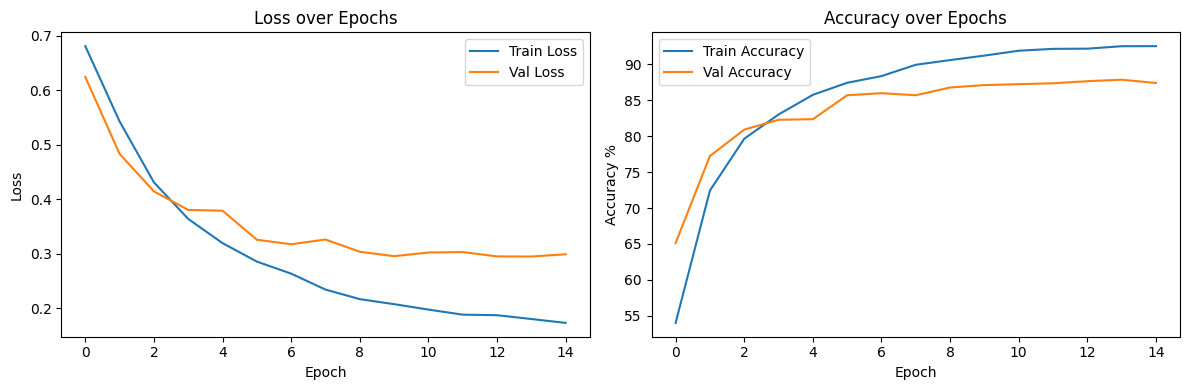

Saved to Google Drive


In [13]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses, label='Train Loss')
ax1.plot(val_losses, label='Val Loss')
ax1.set_title('Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

ax2.plot(train_accs, label='Train Accuracy')
ax2.plot(val_accs, label='Val Accuracy')
ax2.set_title('Accuracy over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy %')
ax2.legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/training_curves_combinednewgatedfusion.png', dpi=150)
plt.show()
print("Saved to Google Drive")
